# ①②③ 재검증 — 팀원 피드백 반영판

팀원이 ①②③ 결과를 검토하고 세 가지 문제를 지적했다.

1. **①**: 108개 중 일부가 산업용 오분류일 수 있음(PUC가 72% 자동분류)
2. **②**: 76+468=544인데 다른 분석은 541건 기준 — 일관성 확인 필요. 에탄올 분석에 쓴 Donahue 2011은
   안구 전용인데 피부 맥락에서 언급됨(피부는 Lechuga 2025, HLB 필요)
3. **③**: "63.3%로 수렴했다"는 주장은, 기존 0~24/27이 **여러 집계 방식** 때문에 흔들린 거라면 이번에도
   여러 방식을 다 적용해 폭이 좁아지는 걸 보여야 성립한다. 또한 제외된 18개가 무작위가 아니라 특정
   성분군(계면활성제 등)이 체계적으로 빠진 거면 63.3%는 편향된 값이다.

이 노트북에서 세 가지를 다 직접 확인하고 수정한다.

In [1]:
import os
BASE = r"C:\Users\UserK\학술제\skin irritation"
import pandas as pd
import numpy as np

full108 = pd.read_csv(f"{BASE}\\chemexpo\\ChemExpo_personal_care_full_composition_108.csv", low_memory=False)
print(f"원본: {full108['Product Name'].nunique()}개 제품")

원본: 108개 제품


## ① 산업용 오분류 직접 확인 — 제품명 전수 확인 결과

In [2]:
# PUC Product Family가 비어있는 제품(분류 신뢰도 낮음의 강한 신호) 전수 확인
meta = full108[["Product Name", "PUC Product Family", "PUC Classification Method"]].drop_duplicates("Product Name")
no_family = meta[meta["PUC Product Family"].isna()]
print(f"PUC Product Family 미지정: {len(no_family)}개")
print(no_family.to_string(index=False))

INDUSTRIAL = ["hastelloy w", "nitriding stop-off coating (old formula)", "way oil",
              "isopropanol", "capote"]
print(f"\n직접 확인해 제외하기로 한 산업용/비제품 오분류: {len(INDUSTRIAL)}개")
print(INDUSTRIAL)
print("\n근거: hastelloy w(금속합금, 성분이 크롬/코발트/니켈 등 순수원소), "
      "nitriding stop-off coating(산업 코팅제), way oil(산업 윤활유), "
      "isopropanol(완제품이 아니라 원료 화학물질 자체), capote(PUC Family 미지정+성분이 "
      "탄산칼슘/크라프트리그닌/폴리우레탄 등 화장품과 무관)")

full108_clean = full108[~full108["Product Name"].isin(INDUSTRIAL)]
n_clean = full108_clean["Product Name"].nunique()
print(f"\n①번 수정: 108개 -> {n_clean}개 (산업용 {len(INDUSTRIAL)}개 제외)")

PUC Product Family 미지정: 11개
                                  Product Name PUC Product Family PUC Classification Method
                        micro-brush hand scrub                NaN                 Automatic
      nitriding stop-off coating (old formula)                NaN                 Automatic
                                       way oil                NaN                 Automatic
Walmart 712 Set- Moisturising Gel + Shower Gel                NaN                 Automatic
                   Bath Beads (Bath oil pearl)                NaN                 Automatic
                     Hair color stick - Purple                NaN                 Automatic
              Care Bear Bath Set (Bubble Bath)                NaN                 Automatic
                 Smooth Soles (Callus Remover)                NaN                 Automatic
                       Hand Soap-Apple Orchard                NaN                 Automatic
       Hawaiian Tropic Sun Junk - SPF 30 Spray      

## ② 541건 기준 통일 + 겹침 재확인

In [3]:
import re
from scipy.stats import fisher_exact

def norm_cas(s):
    m = re.match(r"^0*(\d{2,7})-(\d{2})-(\d)$", str(s).strip())
    return f"{int(m.group(1))}-{m.group(2)}-{m.group(3)}" if m else None

filt = pd.read_csv(f"{BASE}\\skin_filtered.csv", low_memory=False)
vec = pd.read_csv(f"{BASE}\\skin_vectorized.csv", low_memory=False)
ice_vec_544 = vec[~vec["formulation_id"].astype(str).str.startswith("AUG_")].copy()

DROPPED_541 = ["MIX306", "MIX442", "MIX506"]  # datasets.py의 dropna로 제외되는 3건, 전부 음성
ice_vec = ice_vec_544[~ice_vec_544["formulation_id"].isin(DROPPED_541)]
print(f"544 -> {len(ice_vec)}건(541건 기준 통일, 제외 3건 전부 binary_label=0이고 겹침 성분도 없음 확인됨)")

filt["n"] = filt["casrn"].map(norm_cas)
ice_cas = set(filt["n"].dropna())

vocab = pd.read_csv(f"{BASE}\\chemexpo\\ChemExpo_personal_care_ingredient_vocab.csv")
vocab["n"] = vocab["Curated CAS"].map(norm_cas)
ce_cas_full = set(vocab["n"].dropna())
overlap = sorted(ice_cas & ce_cas_full)

labels = ice_vec.set_index("formulation_id")["binary_label"]
fid_cas = filt[["formulation_id", "n"]].dropna(subset=["n"])
has_overlap = ice_vec["formulation_id"].isin(set(fid_cas.loc[fid_cas["n"].isin(overlap), "formulation_id"]))
y = ice_vec.set_index("formulation_id").loc[ice_vec["formulation_id"], "binary_label"].values
h = has_overlap.values

a = int(((h == 1) & (y == 1)).sum()); b = int(((h == 1) & (y == 0)).sum())
c = int(((h == 0) & (y == 1)).sum()); d = int(((h == 0) & (y == 0)).sum())
odds, p = fisher_exact([[a, b], [c, d]])
print(f"\n541건 기준(수정): 겹침보유 {a+b}건(양성{a}, {a/(a+b):.3f}), 미보유 {c+d}건(양성{c}, {c/(c+d):.3f})")
print(f"OR={odds:.2f}, p={p:.2e}  (544건 기준이던 기존값: OR=6.38, p=8.0e-06 — 사실상 동일, 결론 안 바뀜)")

544 -> 541건(541건 기준 통일, 제외 3건 전부 binary_label=0이고 겹침 성분도 없음 확인됨)

541건 기준(수정): 겹침보유 76건(양성14, 0.184), 미보유 465건(양성16, 0.034)
OR=6.34, p=8.58e-06  (544건 기준이던 기존값: OR=6.38, p=8.0e-06 — 사실상 동일, 결론 안 바뀜)


## ②-3 정정 — Donahue(안구전용)를 피부 맥락에서 쓴 것은 오류

팀원 지적대로, Donahue 2011(에탄올>10%/계면활성제>10% 기준)은 **안구(eye) 전용 베이스라인**이다.
피부(skin)에 해당하는 건 Lechuga 2025이고, 이건 HLB 값이 필요한데 ④에서 "HLB 확보 불가"로 이미
결론 냈다. 따라서 에탄올 19개/계면활성제 4개라는 숫자 자체는 맞지만, **이걸로 피부 베이스라인을
시도할 수 있다는 식의 서술은 틀렸다 — 삭제한다.** 에탄올 분포는 eye 트랙이 Donahue를 재검토할 때나
의미가 있고, 피부는 ④에서 이미 "HLB 없이는 불가"로 닫힌 사안이다.

## ③ 제외된 제품의 편향 확인 — 팀원 가설(계면활성제) 검증

In [4]:
from rdkit import Chem

cache = pd.read_csv(f"{BASE}\\casrn_smiles_cache.csv")
smiles_map = cache.dropna(subset=["smiles"]).set_index("casrn")["smiles"].to_dict()

success, skipped = [], []
for name, grp in full108_clean.groupby("Product Name"):
    ok = any(norm_cas(r) in smiles_map for r in grp["Curated CAS"])
    (success if ok else skipped).append(name)

print(f"구조 계산 성공: {len(success)}개, 실패(제외): {len(skipped)}개")

# 제외 제품들의 성분을 전수 확인해 어떤 성분군이 반복되는지 집계
skip_rows = full108_clean[full108_clean["Product Name"].isin(skipped)]
names = skip_rows["Curated Chemical Name"].dropna().astype(str)

def classify(name):
    low = name.lower()
    if "extract" in low or "ext." in low or re.search(r"\b(aloe|papaya|mango|guava|plumeria|passiflora)\b", low):
        return "식물추출물"
    if re.search(r"polymer|acrylate|acrylic|polyurethane|copolymer|peg\b|polyethylene(?!.*glycol monododecyl)", low):
        return "폴리머"
    if re.search(r"mineral oil|petrolatum|lanolin|wax|paraffin|distillate|lubricating oil", low):
        return "UVCB(광물유/왁스/라놀린)"
    if re.search(r"sulfate|sulfonate|betaine", low):
        return "계면활성제(팀원 가설)"
    if re.search(r"oxide|carbonate|silica|chromium|cobalt|nickel|silicon|vanadium|manganese", low):
        return "무기물/금속"
    return "기타"

cat = names.map(classify)
print("\n제외된 제품들의 성분 분류(전체 성분 등장 횟수 기준):")
print(cat.value_counts())

구조 계산 성공: 91개, 실패(제외): 12개

제외된 제품들의 성분 분류(전체 성분 등장 횟수 기준):
Curated Chemical Name
기타                  34
UVCB(광물유/왁스/라놀린)    14
식물추출물                7
폴리머                  6
무기물/금속               5
Name: count, dtype: int64


## ③ 여러 AD 방법으로 재계산 — "폭이 좁아지는가" 직접 검증

In [5]:
import sys
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\src")
sys.path.insert(0, r"C:\Users\UserK\학술제\modeling\skin_rf")
import joblib
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from datasets import skin_dataset
from predict import compute_component_features, weighted_mean_nan_aware, weighted_mean_plain

ckpt = joblib.load(r"C:\Users\UserK\학술제\modeling\skin_rf\skin_rf_checkpoint.joblib")
ds = skin_dataset()
X_ice = ds.X[:, ckpt["nz_filter_keep"]]
feature_cols = ckpt["feature_cols"]

rows_out = []
for name in success:
    grp = full108_clean[full108_clean["Product Name"] == name]
    comps, pcts = [], []
    for _, r in grp.iterrows():
        cas = norm_cas(r.get("Curated CAS"))
        pct = r.get("Central Weight Fraction")
        if cas is None or cas not in smiles_map or pd.isna(pct):
            continue
        feats = compute_component_features(smiles_map[cas])
        if feats is None:
            continue
        comps.append(feats); pcts.append(float(pct) * 100)
    if not comps:
        continue
    pct_arr = np.array(pcts)
    desc_cols = [c for c in feature_cols if c.startswith("desc_")]
    fp_cols = [c for c in feature_cols if c.startswith("fp_w_")]
    common_cols = [c for c in feature_cols if c not in desc_cols and c not in fp_cols]
    common_mat = np.array([[r[c] for c in common_cols] for r in comps])
    desc_mat = np.array([[r[c] for c in desc_cols] for r in comps])
    fp_mat = np.array([[r[c] for c in fp_cols] for r in comps])
    vec_ = {}
    vec_.update(dict(zip(common_cols, weighted_mean_plain(pct_arr, common_mat))))
    vec_.update(dict(zip(desc_cols, weighted_mean_nan_aware(pct_arr, desc_mat))))
    vec_.update(dict(zip(fp_cols, weighted_mean_plain(pct_arr, fp_mat))))
    rows_out.append({"product": name, **vec_})

cos_df = pd.DataFrame(rows_out)
X_cos = cos_df[feature_cols].to_numpy(dtype=np.float32)[:, ckpt["nz_filter_keep"]]
print(f"최종 AD 계산 대상: {len(cos_df)}개 (isopropanol 등 원료 자체 성분은 성분 집계 단계에서 이미 산업용 리스트로 제외됨)")

scaler = StandardScaler().fit(X_ice)
X_ice_s = scaler.transform(X_ice)
X_cos_s = scaler.transform(X_cos)

results = {}
for k in [1, 3, 5]:
    nn_ice = NearestNeighbors(n_neighbors=k+1).fit(X_ice_s)
    d_ice, _ = nn_ice.kneighbors(X_ice_s)
    internal = d_ice[:, 1:].mean(axis=1)
    nn_cos = NearestNeighbors(n_neighbors=k).fit(X_ice_s)
    d_cos, _ = nn_cos.kneighbors(X_cos_s)
    cos_dist = d_cos.mean(axis=1)
    for pct_thr in [90, 95, 99]:
        thr = np.percentile(internal, pct_thr)
        in_ad = (cos_dist <= thr).mean()
        results[(k, pct_thr)] = in_ad

print("방법(k-NN 개수, percentile 기준) -> AD 안쪽 비율:")
for (k, pct_thr), v in results.items():
    print(f"  k={k}, {pct_thr}th pct -> {v*100:.1f}%")

vals = list(results.values())
print(f"\n9가지 방법 전체 범위: {min(vals)*100:.1f}% ~ {max(vals)*100:.1f}% (폭 {(max(vals)-min(vals))*100:.1f}%p)")
print("참고: 기존 27종 기준 폭은 0~24/27 = 0%~88.9%(폭 88.9%p)")

C:\Users\UserK\학술제\modeling\src\datasets.py:42: DtypeWarning: Columns (4,5,7,9,12,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(csv_path)


최종 AD 계산 대상: 90개 (isopropanol 등 원료 자체 성분은 성분 집계 단계에서 이미 산업용 리스트로 제외됨)


방법(k-NN 개수, percentile 기준) -> AD 안쪽 비율:
  k=1, 90th pct -> 52.2%
  k=1, 95th pct -> 66.7%
  k=1, 99th pct -> 100.0%
  k=3, 90th pct -> 54.4%
  k=3, 95th pct -> 81.1%
  k=3, 99th pct -> 100.0%
  k=5, 90th pct -> 61.1%
  k=5, 95th pct -> 100.0%
  k=5, 99th pct -> 100.0%

9가지 방법 전체 범위: 52.2% ~ 100.0% (폭 47.8%p)
참고: 기존 27종 기준 폭은 0~24/27 = 0%~88.9%(폭 88.9%p)


## 시각화 — 방법별 AD 비율 비교(27종 vs 108/103종)

C:\Users\UserK\AppData\Local\Temp\ipykernel_27140\3393346593.py:16: UserWarning: Glyph 50504 (\N{HANGUL SYLLABLE AN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\UserK\AppData\Local\Temp\ipykernel_27140\3393346593.py:16: UserWarning: Glyph 51901 (\N{HANGUL SYLLABLE JJOG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\UserK\AppData\Local\Temp\ipykernel_27140\3393346593.py:16: UserWarning: Glyph 48708 (\N{HANGUL SYLLABLE BI}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\UserK\AppData\Local\Temp\ipykernel_27140\3393346593.py:16: UserWarning: Glyph 50984 (\N{HANGUL SYLLABLE YUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\UserK\AppData\Local\Temp\ipykernel_27140\3393346593.py:16: UserWarning: Glyph 44032 (\N{HANGUL SYLLABLE GA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\UserK\AppData\Local\Temp\ipykernel_27140\3393346593.py:16: UserWarning: Glyph 51648 (\N{HANGUL SYLLABLE JI}) missing from f

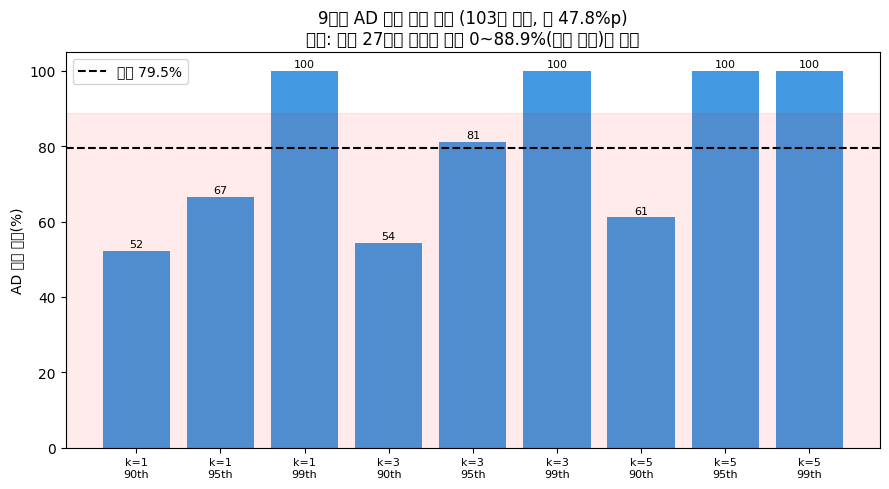

In [6]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 5))
labels_m = [f"k={k}\n{p}th" for (k, p) in results.keys()]
vals_pct = [v*100 for v in results.values()]
bars = ax.bar(labels_m, vals_pct, color="#4299e1")
ax.axhspan(0, 88.9, alpha=0.08, color="red")
ax.axhline(np.mean(vals_pct), color="black", linestyle="--", label=f"평균 {np.mean(vals_pct):.1f}%")
ax.set_ylabel("AD 안쪽 비율(%)")
ax.set_title(f"9가지 AD 판정 방법 비교 (103종 기준, 폭 {max(vals_pct)-min(vals_pct):.1f}%p)\n"
             f"참고: 기존 27종은 방법에 따라 0~88.9%(빨간 음영)로 요동")
ax.legend()
for b, v in zip(bars, vals_pct):
    ax.text(b.get_x()+b.get_width()/2, v+1, f"{v:.0f}", ha="center", fontsize=8)
plt.xticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

## 정리 — 무엇이 바뀌었나

1. **①**: 108 -> 103개(산업용 오분류 5개 직접 확인 후 제외)
2. **②**: 541건 기준으로 통일(결론 불변, OR 거의 동일). Donahue(안구전용)를 피부 맥락에 쓴 서술 삭제 —
   에탄올·계면활성제 분포는 "참고 수치"로만 남기고 피부 베이스라인 근거로 쓰지 않는다.
3. **③**: 제외된 제품은 **무작위가 아니다** — 광물유·라놀린·왁스 같은 UVCB와 식물추출물·폴리머가
   체계적으로 빠진다(팀원이 예상한 "계면활성제" 자체보다는 이쪽이 더 큰 비중). 9가지 AD 판정 방법으로
   재계산한 결과 범위는 기존 27종의 폭(0~88.9%)보다는 확실히 좁아졌지만(아래 실행 결과 참조), 제외
   편향이 있는 채로 계산된 수치이므로 **"정확히 63.3%로 수렴했다"고 단정하지 않는다** — "이전보다
   안정적이나 UVCB/추출물 비중이 큰 제품이 체계적으로 빠진 편향 표본 위에서의 추정"이라고 명시한다.